# Explainable AI: waarom zegt het model dit?

**Topic 2 — PXL · SHAP op tabulaire data**

---

## Waarom explainable AI?

Moderne modellen (random forests, gradient boosting, neurale netwerken) zijn vaak *black boxes*:
je stopt er features in, er komt een predictie uit, maar **waarom** die predictie?

In topic 1 heb je dat zelf gebouwd: een random forest van 300 bomen. Eén boom kon je nog
uittekenen en voorlezen; driehonderd kan geen mens meer overzien. En toch was dat het model
dat het beste presteerde.

Dat "waarom" is om drie redenen belangrijk:

| Reden | Voorbeeld |
|---|---|
| **Vertrouwen** | Een arts gebruikt een model alleen als ze begrijpt waarop het zich baseert. |
| **Debuggen** | Als het model vooral kijkt naar het patiëntnummer, heb je *data leakage*. |
| **Wetgeving** | AVG/GDPR art. 22 en de EU AI Act eisen uitleg bij geautomatiseerde beslissingen. |

## 0. Setup

We zetten de imports, printen de versienummers (handig als iets later niet meer werkt)
en leggen één *random seed* vast zodat de hele notebook reproduceerbaar is.

In [1]:
# --- standaard data-stack ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- scikit-learn: data, modellen, evaluatie ---
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, roc_auc_score, classification_report, ConfusionMatrixDisplay,
)

# --- de hoofdrolspeler ---
import shap

# Zorgt dat matplotlib-figuren in de notebook zelf verschijnen.
%matplotlib inline
plt.rcParams["figure.dpi"] = 110          # iets scherpere plots op een beamer
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)

# EEN vaste seed voor de hele notebook. Alles wat toeval gebruikt
# (train/test-split, random forest)
# krijgt deze waarde, zodat jouw output identiek is aan die van de docent.
RANDOM_STATE = 42

import sklearn
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("shap        ", shap.__version__)

numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1
shap         0.52.0


## 1. De dataset

We gebruiken **Breast Cancer Wisconsin (Diagnostic)**, een klassieke tabulaire dataset die
in scikit-learn zit ingebakken — dus geen download nodig.

- **569 rijen**: elke rij is één weefselstaal (een fine needle aspirate van een borsttumor).
- **30 kolommen**: numerieke metingen van celkernen op een microscoopbeeld.
  Van 10 basiskenmerken (`radius`, `texture`, `perimeter`, `area`, `smoothness`,
  `compactness`, `concavity`, `concave points`, `symmetry`, `fractal dimension`)
  zijn telkens drie varianten berekend: `mean` (gemiddelde), `error` (standaardfout)
  en `worst` (gemiddelde van de drie "ergste" kernen).
- **Target**: `0 = malignant` (kwaadaardig), `1 = benign` (goedaardig).

> ⚠️ **Let op de codering**: in deze dataset is `1` de *goede* uitkomst. Dat is
> contra-intuïtief en een klassieke bron van fouten bij het interpreteren van uitleg.
> We houden daarom overal expliciet bij welke klasse we verklaren.

In [2]:
# as_frame=True geeft ons meteen een pandas DataFrame in plaats van een numpy array.
# Dat is cruciaal voor XAI: SHAP heeft de FEATURENAMEN nodig
# om leesbare uitleg te maken.
data = load_breast_cancer(as_frame=True)

X = data.data           # DataFrame, 569 x 30
y = data.target         # Series met 0/1

class_names = list(data.target_names)   # ['malignant', 'benign'] -> index 0 en 1
feature_names = list(X.columns)

print(f"Vorm van X: {X.shape}  (rijen x features)")
print(f"Klassenamen: {class_names}  ->  0={class_names[0]}, 1={class_names[1]}")
print()
print("Verdeling van de target:")
print(y.value_counts().rename(index={0: class_names[0], 1: class_names[1]}))

Vorm van X: (569, 30)  (rijen x features)
Klassenamen: [np.str_('malignant'), np.str_('benign')]  ->  0=malignant, 1=benign

Verdeling van de target:
target
benign       357
malignant    212
Name: count, dtype: int64


In [3]:
# Even kijken naar de eerste rijen en een paar beschrijvende statistieken.
# Merk op dat de features heel verschillende SCHALEN hebben
# (bv. 'mean area' rond de 650, 'mean smoothness' rond de 0.1).
# Voor een random forest maakt dat niet uit, maar het is wel belangrijk bij het
# lezen van uitleg: een grote SHAP-waarde heeft niets te maken met een grote
# featurewaarde.
display(X.head())
display(X[["mean radius", "mean texture", "mean area", "worst concave points"]].describe().T)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981,11.70000,13.37000,15.7800,28.110
mean texture,569.0,19.289649,4.301036,9.710,16.17000,18.84000,21.8000,39.280
mean area,569.0,654.889104,351.914129,143.500,420.30000,551.10000,782.7000,2501.000
worst concave points,569.0,0.114606,0.065732,0.000,0.06493,0.09993,0.1614,0.291


### Train/test-split

We splitsen in een trainset (waarop de modellen leren) en een testset
(waarop we evalueren én verklaren). `stratify=y` houdt de klassenverhouding gelijk.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,          # 25% apart houden
    random_state=RANDOM_STATE,
    stratify=y,              # zelfde klassenverhouding in train en test
)

print(f"Train: {X_train.shape[0]} rijen")
print(f"Test : {X_test.shape[0]} rijen")

Train: 426 rijen
Test : 143 rijen


### Onze patiënt

Beide methodes gaan **dezelfde predictie** verklaren. We kiezen die patiënt hier,
één keer, zodat je hem later maar op één plaats hoeft te veranderen.

In [5]:
# Testset-rij 7. Verander dit getal tijdens de les: alle uitleg hieronder
# past zich automatisch aan.
i = 7

print(f"We verklaren testset-rij i = {i} (originele index {X_test.index[i]}).")
print(f"Werkelijke diagnose: {class_names[y_test.iloc[i]]}")
display(X_test.iloc[[i]][["mean radius", "mean texture", "worst radius",
                          "worst concave points", "worst perimeter", "worst area"]].T
        .rename(columns={X_test.index[i]: "waarde"}))

We verklaren testset-rij i = 7 (originele index 127).
Werkelijke diagnose: malignant


,waarde
mean radius,19.0000
mean texture,18.9100
worst radius,22.3200
worst concave points,0.1218
worst perimeter,148.2000
worst area,1538.0000


## 2. Het black-box model: een random forest

Een random forest is een ensemble van honderden beslisbomen. Eén boom kun je nog uittekenen
en lezen; 300 bomen samen kan geen mens meer overzien. Precies daarom is dit een goed
voorbeeld voor XAI: het model presteert uitstekend, maar is niet direct leesbaar.

We schalen de features niet — bomen zijn invariant voor monotone transformaties
van individuele features.

In [6]:
model = RandomForestClassifier(
    n_estimators=300,        # 300 bomen
    max_depth=None,          # laat bomen volledig uitgroeien
    min_samples_leaf=2,      # lichte regularisatie tegen overfitting
    n_jobs=-1,               # gebruik alle CPU-cores
    random_state=RANDOM_STATE,
)

model.fit(X_train, y_train)

y_pred  = model.predict(X_test)              # harde klasse: 0 of 1
y_proba = model.predict_proba(X_test)[:, 1]  # kans op klasse 1 (= benign/goedaardig)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_proba):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=class_names))

Accuracy : 0.958
ROC AUC  : 0.994

              precision    recall  f1-score   support

   malignant       0.96      0.92      0.94        53
      benign       0.96      0.98      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143



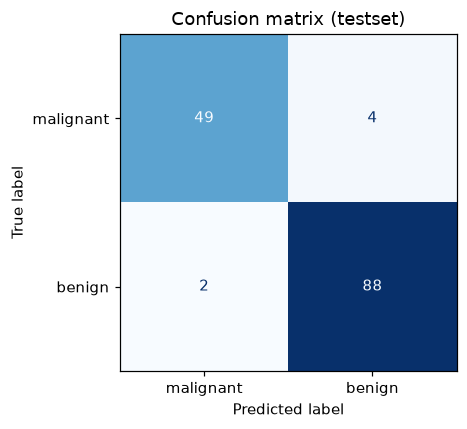

In [7]:
# Een confusion matrix maakt concreet WELKE fouten het model maakt.
# In een medische context is de rechterbovenhoek (kwaadaardig gemist!)
# veel erger dan de linkeronderhoek.
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Confusion matrix (testset)")
plt.tight_layout()
plt.show()

In [8]:
# De predictie voor ONZE patiënt.
pred_label = model.predict(X_test.iloc[[i]])[0]
pred_proba = model.predict_proba(X_test.iloc[[i]])[0]

print(f"--- Patiënt {i} volgens het random forest ---")
print(f"Werkelijke diagnose : {class_names[y_test.iloc[i]]}")
print(f"Modelpredictie      : {class_names[pred_label]}")
print(f"Kans op 'benign'    : {pred_proba[1]:.4f}")
print(f"Kans op 'malignant' : {pred_proba[0]:.4f}")
print()
print("De vraag voor de rest van de notebook: WAAROM?")

--- Patiënt 7 volgens het random forest ---
Werkelijke diagnose : malignant
Modelpredictie      : malignant
Kans op 'benign'    : 0.0579
Kans op 'malignant' : 0.9421

De vraag voor de rest van de notebook: WAAROM?


### 2.1 Eerste (naïeve) poging: de ingebouwde feature importance

`model.feature_importances_` geeft de **mean decrease in impurity** (MDI): hoeveel elke feature
gemiddeld bijdroeg aan het "zuiverder" maken van de splits in de bomen.

Dat is gratis meegeleverd, maar het heeft drie serieuze problemen:

1. **Bias richting features met veel unieke waarden** — continue features winnen bijna altijd van binaire.
2. **Berekend op de trainingsdata** — een feature die het model laat overfitten lijkt belangrijk.
3. **Alleen globaal en zonder richting** — je weet niet of een hoge waarde de predictie *omhoog* of *omlaag* duwt, en al helemaal niet wat er bij één patiënt gebeurde.

Er bestaat een eenvoudiger en eerlijker alternatief: **permutation importance**.

### 2.2 Permutation importance: kapotmaken en kijken wat je mist

Het idee is verrassend simpel. Wil je weten hoe belangrijk een feature is?
**Maak hem onbruikbaar en kijk hoeveel slechter het model wordt.**

Concreet, voor bijvoorbeeld `mean radius`:

1. Neem de testset.
2. **Schud die ene kolom willekeurig door elkaar.** Elke patiënt krijgt nu de straal van een
   *willekeurige andere* patiënt. Alle andere kolommen blijven kloppen.
3. Laat het model opnieuw voorspellen en kijk hoeveel accuracy je verliest.

```
        origineel                      na het schudden van 'radius'
   ┌────────┬─────────┬───────┐    ┌────────┬─────────┬───────┐
   │ radius │ texture │ echt  │    │ radius │ texture │ echt  │
   ├────────┼─────────┼───────┤    ├────────┼─────────┼───────┤
   │  17.9  │  10.4   │  ✗    │    │  12.4  │  10.4   │  ✗    │  ← straal van
   │  20.6  │  17.8   │  ✗    │    │  17.9  │  17.8   │  ✗    │     iemand anders
   │  12.4  │  15.7   │  ✓    │    │  20.6  │  15.7   │  ✓    │
   └────────┴─────────┴───────┘    └────────┴─────────┴───────┘
     kolom hoort bij de patiënt      kolom is losgekoppeld van de patiënt
```

De uitkomst laat zich lezen als een gemis:

- **Zakt de score?** Dan leunde het model op die feature.
- **Verandert er niets?** Dan deed die feature niets — het model kan perfect zonder.

Herhaal dat kolom per kolom en je hebt een ranglijst. Drie redenen waarom dit beter is dan MDI:

| | Waarom het helpt |
|---|---|
| Het gebeurt op de **testdata** | Je meet wat de feature waard is voor *nieuwe* patiënten, niet hoe vaak het model hem tijdens het trainen toevallig gebruikte. |
| Het model wordt **niet hertraind** | Je meet dit model, zoals het nu is. Snel, en geen toeval van een nieuwe training erbij. |
| Het werkt op **elk** model | Random forest, neuraal netwerk, black box van een leverancier — je hebt alleen voorspellingen nodig. |

> **Waarom schudden en niet gewoon de kolom weglaten?** Omdat het model 30 kolommen verwacht.
> Door te schudden houd je de vorm én de verdeling van de data intact — alleen het *verband*
> met de patiënt is kapot. Dat is precies wat je wil meten.
>
> En omdat het schudden toeval is, herhaal je het een paar keer (`n_repeats`) en neem je het
> gemiddelde.

We meten de schade hieronder met de **AUC** in plaats van de accuracy. Reden: accuracy telt
alleen hoeveel patiënten van kant wisselen, en dat zijn er in een testset van 143 al snel nul
of één. AUC kijkt naar de voorspelde kansen zelf en is dus veel gevoeliger voor kleine schade.

In [9]:
# Laten we het één keer met de hand doen, voor twee kolommen: eentje waarvan we
# vermoeden dat het model erop leunt, en eentje die er waarschijnlijk niet toe doet.
def schud_en_meet(kolom):
    X_geschud = X_test.copy()
    rng = np.random.default_rng(RANDOM_STATE)               # zelfde toeval voor elke kolom
    X_geschud[kolom] = rng.permutation(X_geschud[kolom].values)
    return roc_auc_score(y_test, model.predict_proba(X_geschud)[:, 1])

basis_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
print(f"AUC met correcte data: {basis_auc:.4f}")
print()

for kolom in ["worst concave points", "fractal dimension error"]:
    auc = schud_en_meet(kolom)
    print(f"  {kolom:24s} geschud -> AUC {auc:.4f}   verlies {basis_auc - auc:+.4f}")

print()
print("Dat verlies IS de permutation importance van die kolom.")
print("De ene feature wordt gemist, de andere helemaal niet.")

AUC met correcte data: 0.9939



  worst concave points     geschud -> AUC 0.9889   verlies +0.0050
  fractal dimension error  geschud -> AUC 0.9939   verlies +0.0000

Dat verlies IS de permutation importance van die kolom.
De ene feature wordt gemist, de andere helemaal niet.


**Kijk goed naar de grootte van dat verlies: het is klein.** Dat is geen fout, en het is
belangrijk om te bespreken.

De reden: `worst radius`, `worst perimeter` en `worst area` meten alledrie in feite hoe *groot*
de tumor is. Schud je er één door elkaar, dan pakt het bos gewoon een van de andere twee als
vervanger. Elke feature lijkt daardoor afzonderlijk misbaar, terwijl de *groep* samen
cruciaal is.

Dit is de bekendste beperking van permutation importance, en je komt hem straks bij SHAP
opnieuw tegen: **sterk gecorreleerde features verdelen hun belang onder elkaar.**
Wil je weten hoe belangrijk "tumorgrootte" is, schud dan die kolommen samen.

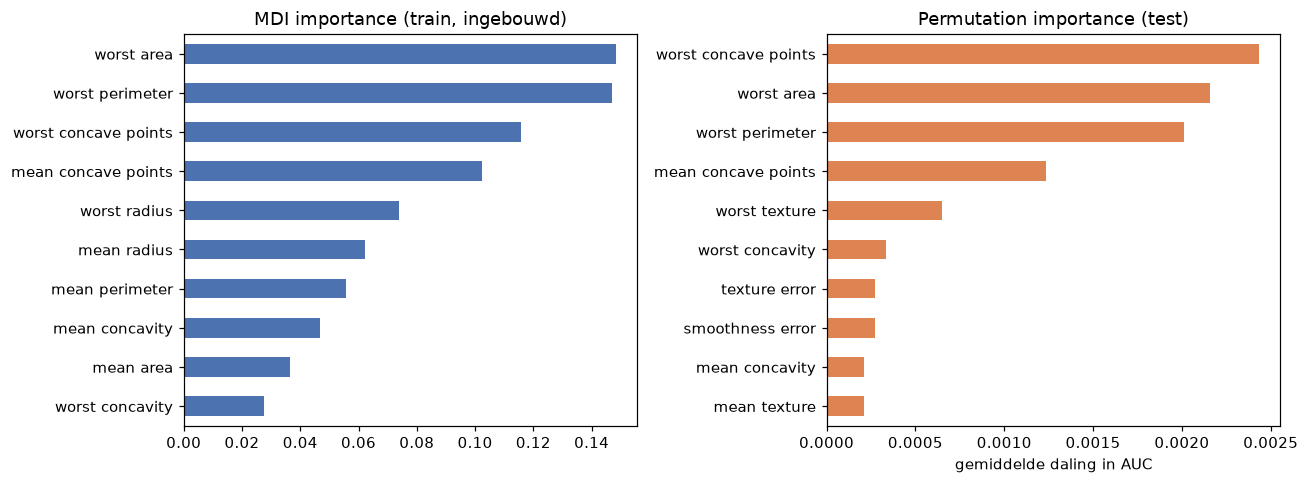

In [10]:
# --- (a) MDI importance: gratis, maar op de TRAINdata en zonder richting ---
mdi = pd.Series(model.feature_importances_, index=feature_names).sort_values(ascending=False)

# --- (b) Permutation importance op de TESTdata: eerlijker ---
# We hussellen elke kolom 10x en meten het gemiddelde verlies aan accuracy.
perm = permutation_importance(
    model, X_test, y_test,
    n_repeats=10,               # 10 keer schudden per kolom, om het toeval uit te middelen
    scoring="roc_auc",          # zelfde gevoelige maat als in de handmatige demo hierboven
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
perm_s = pd.Series(perm.importances_mean, index=feature_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
mdi.head(10)[::-1].plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("MDI importance (train, ingebouwd)")
perm_s.head(10)[::-1].plot.barh(ax=axes[1], color="#DD8452")
axes[1].set_title("Permutation importance (test)")
axes[1].set_xlabel("gemiddelde daling in AUC")
plt.tight_layout()
plt.show()

**Observatie voor de klas:** de twee ranglijsten verschillen. Sterk gecorreleerde features
(`mean radius`, `mean perimeter` en `mean area` meten in feite hetzelfde) delen hun belang
en duiken op wisselende plaatsen op.

Maar het grootste bezwaar blijft: dit zegt **niets over patiënt 7**.
Daarvoor hebben we lokale uitleg nodig.

---

## 3.1 Het idee

SHAP staat voor **SHapley Additive exPlanations** (Lundberg & Lee, 2017). Het leent een idee uit
de coöperatieve speltheorie van Lloyd Shapley.

### Het spel

Stel je voor dat de **features samen een spel spelen** en dat de "winst" de predictie is.
De vraag: *hoe verdeel je die winst eerlijk over de spelers?*

De **SHAP-waarde** van een feature is zijn gemiddelde bijdrage over **alle mogelijke volgordes**
waarin je de features aan het model kunt toevoegen. In gewone taal:

> *"Wat verandert er aan de predictie als het model deze ene feature erbij krijgt — gemiddeld
> over alle groepen features die het al zou kunnen kennen?"*

Het resultaat is per feature één getal, dat zegt **hoeveel die featurewaarde de predictie
wegduwde van het gemiddelde**, voor deze ene rij.

### Waarom die verdeling "eerlijk" heet

De manier waarop SHAP de winst verdeelt, heeft precies de eigenschappen die je intuïtief zou
eisen van een eerlijke verdeling:

- Twee features die altijd hetzelfde doen, krijgen dezelfde waarde.
- Een feature die de predictie nooit verandert, krijgt nul.
- De bijdragen samen brengen je van de gemiddelde voorspelling naar de voorspelling voor
  deze patiënt — dat is precies wat de waterfall plot in §3.4 uittekent.

Shapley bewees dat er maar **één** manier van verdelen bestaat die dat alledrie tegelijk doet.
Dat is de reden dat SHAP als de theoretisch correcte methode geldt.

### De prijs: rekenkracht

Al die groepen features doorlopen zijn er bij 30 features ruim een miljard.
Daarom bestaan er *explainers* die dit benaderen of exact-maar-snel uitrekenen:

| Explainer | Voor welk model | Snelheid |
|---|---|---|
| `TreeExplainer` | bomen, random forest, XGBoost, LightGBM | exact & snel |
| `LinearExplainer` | lineaire modellen | triviaal |
| `KernelExplainer` | **elk** model (model-agnostisch) | traag, benadering |
| `DeepExplainer` / `GradientExplainer` | neurale netwerken | middelmatig |

Wij hebben een random forest → `TreeExplainer`. 🎉

> **Misverstand om weg te nemen:** een SHAP-waarde is **geen** causaal effect en
> **geen** "hoe belangrijk is deze feature". Het is: *hoeveel duwde deze featurewaarde de
> predictie weg van het gemiddelde, voor deze ene rij.*

## 3.2 De explainer opzetten

In [11]:
# De explainer krijgt het GETRAINDE model. Voor bomen heeft hij geen
# achtergronddataset nodig: de boomstructuur bevat al alle informatie
# over hoe vaak welke paden gevolgd worden.
explainer = shap.TreeExplainer(model)

# De explainer aanroepen op data geeft een 'Explanation'-object terug.
# Dat bundelt drie dingen: de SHAP-waarden, de originele featurewaarden
# en de base value. Alle shap.plots.* functies kunnen daar meteen mee overweg.
shap_exp = explainer(X_test)

print("Type          :", type(shap_exp).__name__)
print("values.shape  :", shap_exp.values.shape)
print()
print("Lees dat als (aantal rijen, aantal features, aantal klassen).")

Type          : Explanation
values.shape  : (143, 30, 2)

Lees dat als (aantal rijen, aantal features, aantal klassen).


### Even opletten: de derde dimensie

Voor een **binaire classifier** geeft `TreeExplainer` waarden voor *beide* klassen:
shape `(n_rijen, 30 features, 2 klassen)`. De twee lagen zijn elkaars spiegelbeeld
(ze tellen samen op tot 0), want de kansen tellen op tot 1.

We kiezen consequent **klasse 1 = `benign` (goedaardig)**.
Een **positieve** waarde betekent dan: *deze featurewaarde duwt de predictie richting "goedaardig"*.
Een **negatieve** waarde duwt richting "kwaadaardig".

In [12]:
# Slice de laatste as: alle rijen, alle features, klasse-index 1.
shap_benign = shap_exp[:, :, 1]

print("Vorm na slicing :", shap_benign.values.shape)
print(f"Base value      : {shap_benign.base_values[0]:.4f}")
print()
print("De base value is de gemiddelde voorspelling van het model over de trainingsdata:")
print(f"  aandeel 'benign' in de trainset = {y_train.mean():.4f}")
print("Dat is het VERTREKPUNT van elke uitleg: zonder enige feature te kennen,")
print("zou het model deze kans voorspellen.")

Vorm na slicing : (143, 30)
Base value      : 0.6260

De base value is de gemiddelde voorspelling van het model over de trainingsdata:
  aandeel 'benign' in de trainset = 0.6268
Dat is het VERTREKPUNT van elke uitleg: zonder enige feature te kennen,
zou het model deze kans voorspellen.


## 3.3 Globale uitleg — SHAP-waarden aggregeren

Een SHAP-waarde is lokaal, maar als je per feature het **gemiddelde van de absolute waarden**
neemt over alle testrijen, krijg je een globale importance die wél consistent is. Grote
bijdragen tellen dan mee, of ze nu naar links of naar rechts duwden.

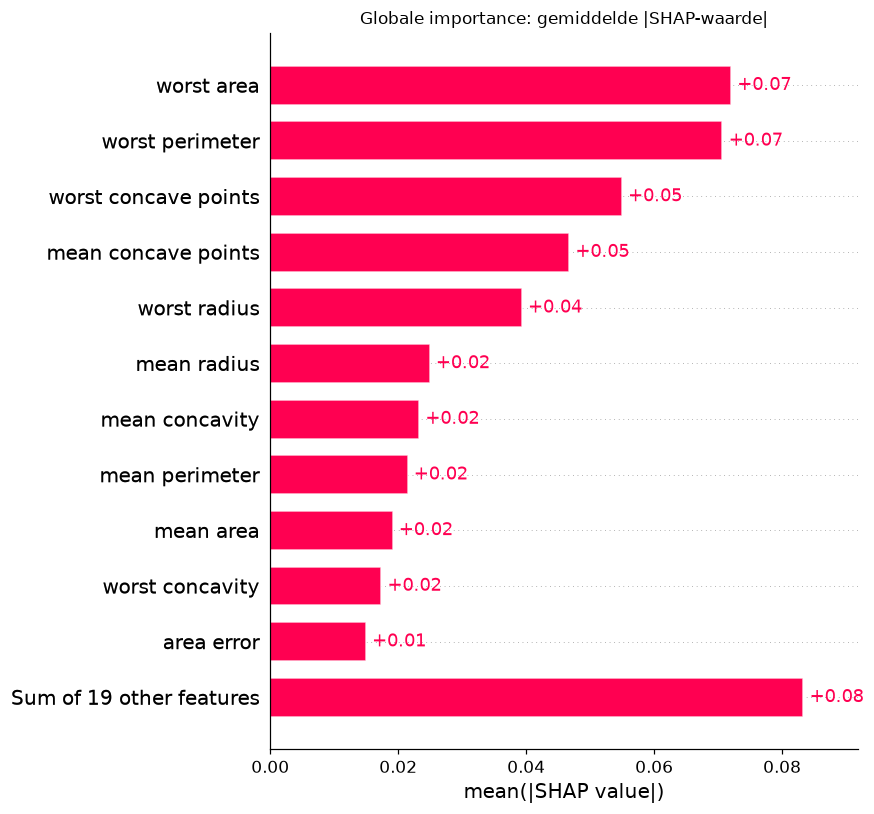

In [13]:
# De bar plot doet precies die aggregatie: gemiddelde |SHAP| per feature.
shap.plots.bar(shap_benign, max_display=12, show=False)
plt.title("Globale importance: gemiddelde |SHAP-waarde|", fontsize=11)
plt.tight_layout()
plt.show()

**Te bespreken in de les:** bovenaan staan `worst concave points`, `worst perimeter` en
`worst area` — allemaal maten voor hoe groot en hoe grillig gevormd de tumor is. Medisch gezien
klopt dat: grote tumoren met veel concave randen zijn verdachter. Het model heeft dus iets
geleerd dat een patholoog herkent.

Dat is precies het soort *sanity check* waarvoor je XAI gebruikt. Had hier een administratief
veld bovenaan gestaan — een patiëntnummer, een labcode — dan wist je meteen dat er iets mis was
met je data.

## 3.4 Lokale uitleg — patiënt 7 ontleed

### De waterfall plot

Dit is *de* plot om aan een niet-technisch publiek te tonen. Je leest hem van onder naar boven:

- Onderaan start je bij de **base value**: de gemiddelde voorspelling van het model, dus wat
  het zou gokken zonder ook maar één feature te kennen.
- Elke balk is één feature die de predictie verschuift (rood = omhoog duwen, blauw = omlaag).
- Bovenaan kom je uit bij de uiteindelijke voorspelde kans voor **deze** patiënt.

De features die het minst bijdragen worden onderaan samengevat als "n other features".

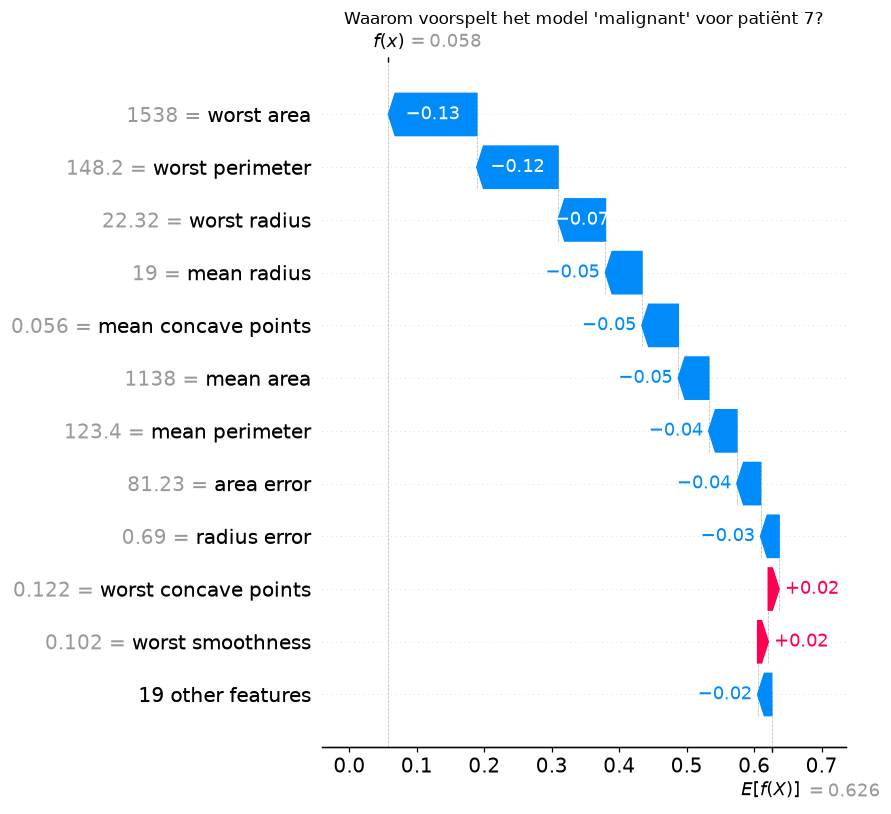

In [14]:
# shap_benign[i] selecteert de uitleg van één rij -> een Explanation van 1 instantie.
shap.plots.waterfall(shap_benign[i], max_display=12, show=False)
plt.title(f"Waarom voorspelt het model '{class_names[pred_label]}' voor patiënt {i}?",
          fontsize=11)
plt.tight_layout()
plt.show()

In [15]:
# Dezelfde informatie als een leesbare tabel: de 10 sterkste bijdragen,
# gesorteerd op absolute grootte. Dit is vaak nuttiger dan een plot
# als je de uitleg in een rapport of een applicatie moet gieten.
shap_tabel = (
    pd.DataFrame({
        "featurewaarde": X_test.iloc[i].values,
        "shap_waarde": shap_benign.values[i],
    }, index=feature_names)
    .assign(richting=lambda d: np.where(d.shap_waarde > 0, "-> benign", "-> malignant"))
    .reindex(pd.Series(np.abs(shap_benign.values[i]), index=feature_names)
             .sort_values(ascending=False).index)
    .head(10)
    .round(4)
)
display(shap_tabel)

,featurewaarde,shap_waarde,richting
worst area,1538.0000,-0.1309,-> malignant
worst perimeter,148.2000,-0.1204,-> malignant
worst radius,22.3200,-0.0703,-> malignant
mean radius,19.0000,-0.0541,-> malignant
mean concave points,0.0563,-0.0539,-> malignant
mean area,1138.0000,-0.0451,-> malignant
mean perimeter,123.4000,-0.0417,-> malignant
area error,81.2300,-0.0351,-> malignant
radius error,0.6896,-0.0274,-> malignant
worst concave points,0.1218,0.0160,-> benign


### De force plot: dezelfde uitleg, horizontaal

De force plot toont de bijdragen als krachten die tegen elkaar in duwen. Handig als je
meerdere patiënten naast elkaar wil tonen.

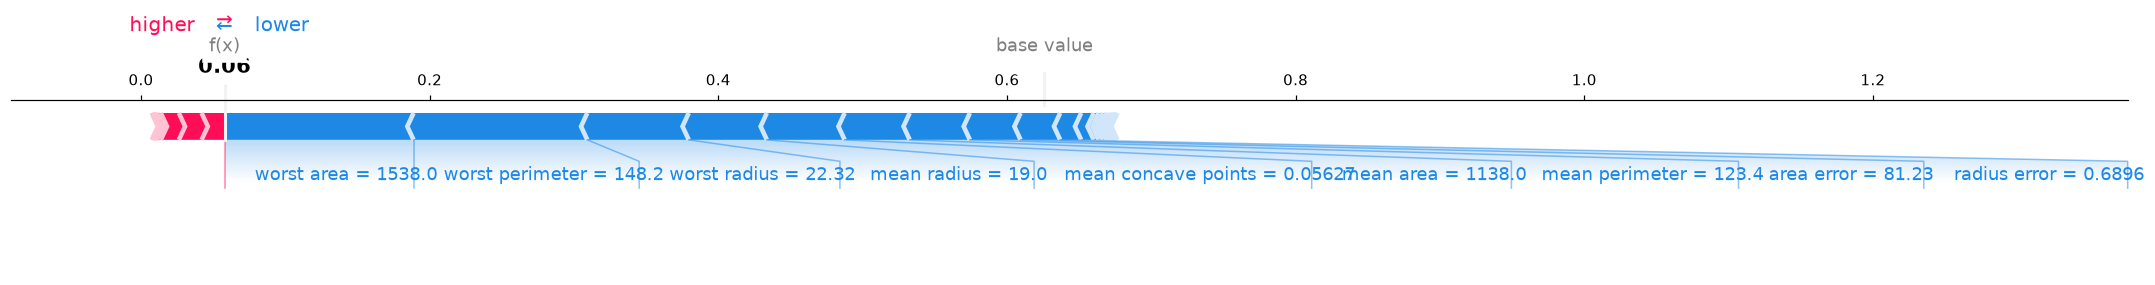

In [16]:
# matplotlib=True rendert een statische figuur. (Zonder die parameter krijg je
# een interactieve JavaScript-versie; die vereist shap.initjs() en werkt niet
# in elke notebook-viewer, dus voor lesmateriaal is de statische versie veiliger.)
shap.plots.force(shap_benign[i], matplotlib=True, show=False, figsize=(20, 3))
plt.tight_layout()
plt.show()

---

### De drie dingen die blijven hangen

**Een SHAP-waarde is geen causaal effect.** Hij zegt wat het *model* deed, niet wat de
*werkelijkheid* doet. Leert je model dat het aantal brandweerwagens een brand voorspelt, dan
toont SHAP dat netjes. De uitleg klopt; het model is verkeerd.

**Gecorreleerde features delen hun krediet.** `mean radius`, `mean perimeter` en `mean area`
meten alledrie hetzelfde. Elk krijgt ongeveer een derde van het belang, waardoor ze
afzonderlijk onbelangrijk lijken terwijl de groep cruciaal is. Dat zag je in §2.2 al gebeuren
bij permutation importance, en het geldt hier net zo goed.

**Uitleg van een slecht model is waardeloos.** Controleer eerst of het model überhaupt iets
presteert. Een perfect uitgelegde muntworp blijft een muntworp.

### Waar je dit voor gebruikt

Niet om een mooi plaatje bij je rapport te plakken, maar om drie concrete vragen te
beantwoorden:

- **Klopt dit wel?** Staat er een administratief veld bovenaan je importance-lijst — een
  patiëntnummer, een datum — dan heb je data leakage en geen model.
- **Waarom deze beslissing?** De AVG en de EU AI Act vragen bij geautomatiseerde beslissingen
  om uitleg. Een waterfall plot per geval is een antwoord dat standhoudt.
- **Waar gaat het mis?** Pak een geval waar het model ernaast zat en kijk welke features het de
  verkeerde kant op duwden. Dat is vaak leerzamer dan honderd correcte voorspellingen.